<a href="https://colab.research.google.com/github/keerthanajeyashree25-eng/AI-Government-Assistant/blob/main/Dimensionality_Reduction_Unsupervised_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dimensionality Reduction & Unsupervised Clustering

**Objective:** Standardize numerical features, apply PCA, choose a useful number of components, and compare K-Means, DBSCAN, and Hierarchical clustering.

This notebook is designed for Google Colab. Upload your CSV dataset when prompted. The target/class column (if any) is not used for clustering.

In [1]:
# 1. Import libraries
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.neighbors import NearestNeighbors

sns.set_theme(style="whitegrid")
print("Libraries imported successfully")

Libraries imported successfully


## 2. Upload and inspect the dataset

Run the cell and choose your `.csv` file. If your data is already in Google Drive, you can replace this upload section with a Drive mount and a `pd.read_csv()` path.

In [3]:
from google.colab import files

uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset shape:", df.shape)
display(df.head())
display(df.info())

Saving archive (1).zip to archive (1).zip
Dataset shape: (1143, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1143 entries, 0 to 1142
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1143 non-null   float64
 1   volatile acidity      1143 non-null   float64
 2   citric acid           1143 non-null   float64
 3   residual sugar        1143 non-null   float64
 4   chlorides             1143 non-null   float64
 5   free sulfur dioxide   1143 non-null   float64
 6   total sulfur dioxide  1143 non-null   float64
 7   density               1143 non-null   float64
 8   pH                    1143 non-null   float64
 9   sulphates             1143 non-null   float64
 10  alcohol               1143 non-null   float64
 11  quality               1143 non-null   int64  
 12  Id                    1143 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 116.2 KB


None

In [4]:
# 3. Prepare numerical features
# Clustering requires numerical features. Non-numeric columns are excluded automatically.
numeric_df = df.select_dtypes(include=np.number).copy()

if numeric_df.shape[1] < 2:
    raise ValueError("At least two numerical columns are required for PCA and clustering.")

# Remove columns that contain no usable values or are constant
numeric_df = numeric_df.dropna(axis=1, how="all")
numeric_df = numeric_df.loc[:, numeric_df.nunique(dropna=True) > 1]

if numeric_df.shape[1] < 2:
    raise ValueError("At least two non-constant numerical columns are required.")

imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(numeric_df)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

print("Numerical features used:", list(numeric_df.columns))
print("Prepared data shape:", X_scaled.shape)

Numerical features used: ['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol', 'quality', 'Id']
Prepared data shape: (1143, 13)


## 4. Principal Component Analysis (PCA)

PCA transforms the standardized features into principal components. The scree plot and cumulative explained variance help decide how many components retain most of the information.

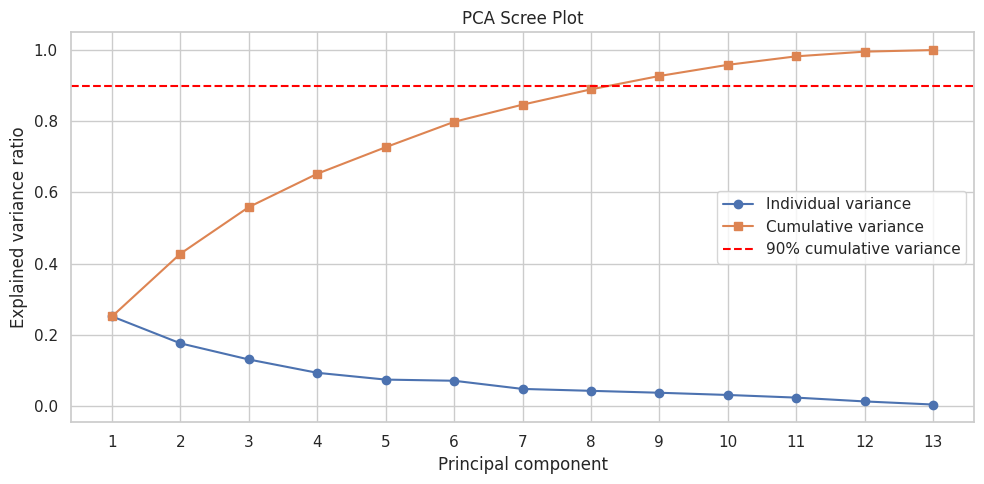

Components needed to retain at least 90% variance: 9
Variance retained by selected components: 0.5591


In [5]:
pca_full = PCA()
X_pca_full = pca_full.fit_transform(X_scaled)

explained = pca_full.explained_variance_ratio_
cumulative = np.cumsum(explained)

plt.figure(figsize=(10, 5))
plt.plot(range(1, len(explained) + 1), explained, marker="o", label="Individual variance")
plt.plot(range(1, len(cumulative) + 1), cumulative, marker="s", label="Cumulative variance")
plt.axhline(0.90, color="red", linestyle="--", label="90% cumulative variance")
plt.xlabel("Principal component")
plt.ylabel("Explained variance ratio")
plt.title("PCA Scree Plot")
plt.xticks(range(1, len(explained) + 1))
plt.legend()
plt.tight_layout()
plt.show()

n_components_90 = int(np.argmax(cumulative >= 0.90) + 1)
print("Components needed to retain at least 90% variance:", n_components_90)

# Use up to 3 components for cluster visualizations
n_components = min(3, X_scaled.shape[1])
pca = PCA(n_components=n_components)
X_pca = pca.fit_transform(X_scaled)
print("Variance retained by selected components:", round(pca.explained_variance_ratio_.sum(), 4))

## 5. K-Means: Elbow Method and Silhouette Score

The Elbow Method compares within-cluster sum of squares (inertia). The silhouette score measures how well-separated the clusters are. Use both plots to guide the choice of `k`.

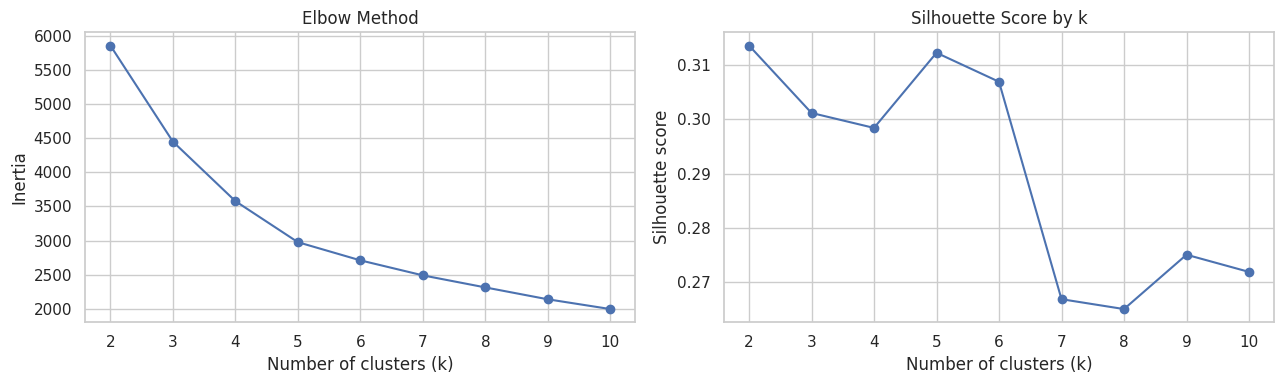

Best k based on silhouette score: 2


In [6]:
max_k = min(10, len(X_pca) - 1)
if max_k < 2:
    raise ValueError("At least 3 rows are needed for clustering analysis.")

k_values = list(range(2, max_k + 1))
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_pca)
    inertias.append(model.inertia_)
    silhouette_scores.append(silhouette_score(X_pca, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(k_values, inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_values, silhouette_scores, marker="o")
axes[1].set_title("Silhouette Score by k")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()

best_k = k_values[int(np.argmax(silhouette_scores))]
print("Best k based on silhouette score:", best_k)

In [7]:
# 6. Fit final K-Means model
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_pca)

print("K-Means silhouette score:", round(silhouette_score(X_pca, kmeans_labels), 4))
print(pd.Series(kmeans_labels).value_counts().sort_index())

K-Means silhouette score: 0.3136
0    755
1    388
Name: count, dtype: int64


## 7. Visualize K-Means clusters in 2D and 3D

The first two principal components provide a 2D projection. If at least three components are available, the notebook also creates an interactive Plotly 3D projection.

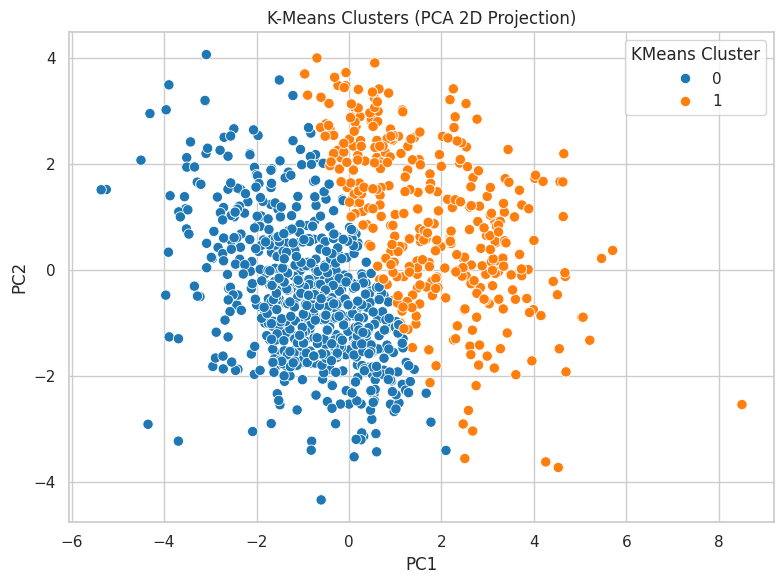

In [8]:
plot_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "KMeans Cluster": kmeans_labels.astype(str)
})

plt.figure(figsize=(8, 6))
sns.scatterplot(data=plot_df, x="PC1", y="PC2", hue="KMeans Cluster", palette="tab10", s=55)
plt.title("K-Means Clusters (PCA 2D Projection)")
plt.tight_layout()
plt.show()

if X_pca.shape[1] >= 3:
    import plotly.express as px
    plot3d = pd.DataFrame({
        "PC1": X_pca[:, 0], "PC2": X_pca[:, 1], "PC3": X_pca[:, 2],
        "Cluster": kmeans_labels.astype(str)
    })
    fig = px.scatter_3d(plot3d, x="PC1", y="PC2", z="PC3", color="Cluster",
                        title="K-Means Clusters (PCA 3D Projection)")
    fig.show()
else:
    print("3D plot skipped: fewer than 3 principal components are available.")

## 8. DBSCAN clustering

DBSCAN identifies dense groups and can label unusual observations as noise (`-1`). Its result depends on `eps` and `min_samples`; the k-distance plot below can help select `eps`. The code uses a starting value based on the data and reports the result so you can tune it if needed.

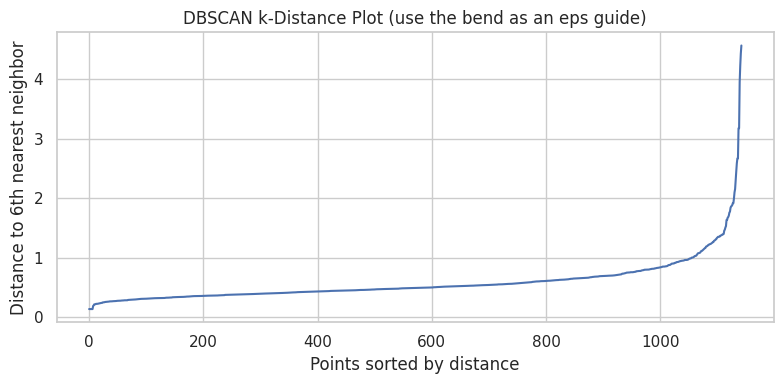

DBSCAN eps: 0.9196
DBSCAN clusters (excluding noise): 1
Noise points: 62
Silhouette score not calculated: DBSCAN found fewer than 2 usable clusters.


In [9]:
min_samples = max(4, 2 * X_pca.shape[1])

neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_pca)
distances, _ = neighbors_fit.kneighbors(X_pca)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 4))
plt.plot(k_distances)
plt.xlabel("Points sorted by distance")
plt.ylabel(f"Distance to {min_samples}th nearest neighbor")
plt.title("DBSCAN k-Distance Plot (use the bend as an eps guide)")
plt.tight_layout()
plt.show()

# Starting eps: 90th percentile of k-distances; adjust after inspecting the plot
eps_value = float(np.percentile(k_distances, 90))
dbscan = DBSCAN(eps=eps_value, min_samples=min_samples)
dbscan_labels = dbscan.fit_predict(X_pca)

n_db_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_noise = int(np.sum(dbscan_labels == -1))
print("DBSCAN eps:", round(eps_value, 4))
print("DBSCAN clusters (excluding noise):", n_db_clusters)
print("Noise points:", n_noise)

valid_db = dbscan_labels != -1
if n_db_clusters >= 2 and valid_db.sum() > n_db_clusters:
    print("DBSCAN silhouette (excluding noise):",
          round(silhouette_score(X_pca[valid_db], dbscan_labels[valid_db]), 4))
else:
    print("Silhouette score not calculated: DBSCAN found fewer than 2 usable clusters.")

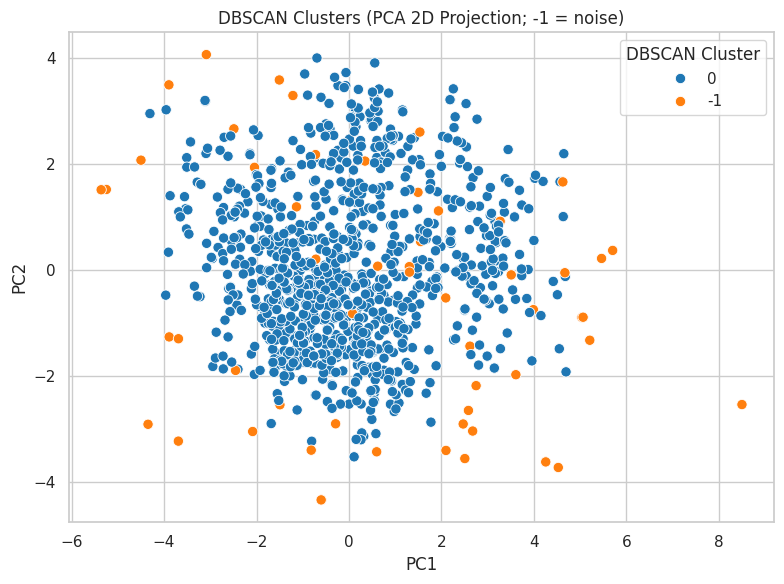

In [10]:
# DBSCAN 2D visualization
db_plot = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "DBSCAN Cluster": dbscan_labels.astype(str)
})
plt.figure(figsize=(8, 6))
sns.scatterplot(data=db_plot, x="PC1", y="PC2", hue="DBSCAN Cluster",
                palette="tab10", s=55)
plt.title("DBSCAN Clusters (PCA 2D Projection; -1 = noise)")
plt.tight_layout()
plt.show()

## 9. Hierarchical (Agglomerative) clustering

Agglomerative clustering builds nested groups by repeatedly merging observations/clusters. For a readable dendrogram, the notebook samples up to 500 rows. The final cluster labels are fitted on the full PCA dataset.

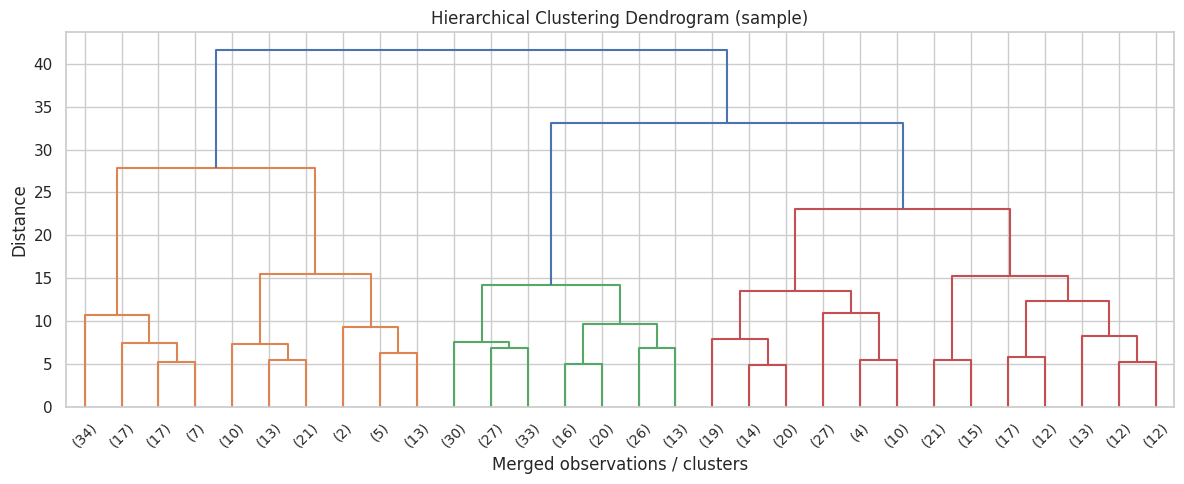

Hierarchical silhouette score: 0.2808


In [11]:
from scipy.cluster.hierarchy import linkage, dendrogram

sample_size = min(500, len(X_pca))
rng = np.random.default_rng(42)
sample_indices = rng.choice(len(X_pca), size=sample_size, replace=False) if sample_size < len(X_pca) else np.arange(len(X_pca))

Z = linkage(X_pca[sample_indices], method="ward")
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=30)
plt.title("Hierarchical Clustering Dendrogram (sample)")
plt.xlabel("Merged observations / clusters")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()

hierarchical = AgglomerativeClustering(n_clusters=best_k, linkage="ward")
hierarchical_labels = hierarchical.fit_predict(X_pca)
print("Hierarchical silhouette score:",
      round(silhouette_score(X_pca, hierarchical_labels), 4))

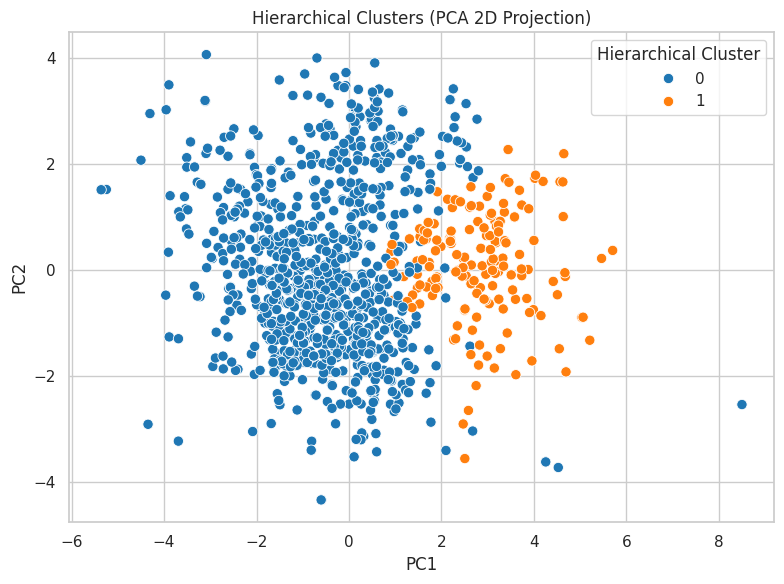

In [12]:
# Hierarchical clustering 2D visualization
hier_plot = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Hierarchical Cluster": hierarchical_labels.astype(str)
})
plt.figure(figsize=(8, 6))
sns.scatterplot(data=hier_plot, x="PC1", y="PC2",
                hue="Hierarchical Cluster", palette="tab10", s=55)
plt.title("Hierarchical Clusters (PCA 2D Projection)")
plt.tight_layout()
plt.show()

## 10. Compare clustering algorithms

Compare silhouette scores for K-Means, Hierarchical, and DBSCAN when DBSCAN produces at least two non-noise clusters. A higher silhouette score generally indicates better separation, but interpret it together with the plots and the amount of DBSCAN noise.

,Algorithm,Silhouette Score
0,K-Means,0.313636
1,Hierarchical,0.280754


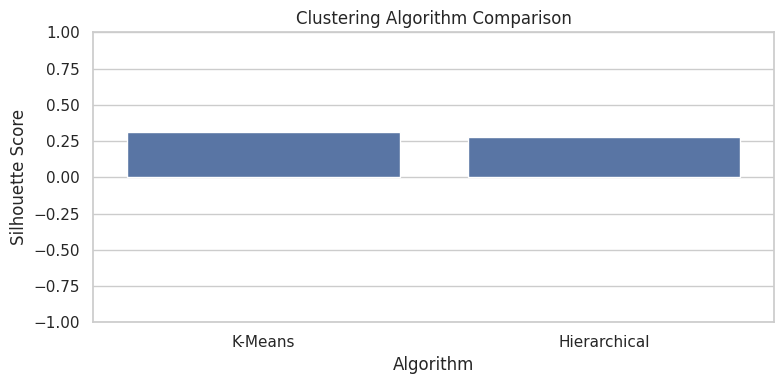

In [13]:
comparison = {
    "K-Means": silhouette_score(X_pca, kmeans_labels),
    "Hierarchical": silhouette_score(X_pca, hierarchical_labels)
}

if n_db_clusters >= 2 and valid_db.sum() > n_db_clusters:
    comparison["DBSCAN (non-noise points)"] = silhouette_score(
        X_pca[valid_db], dbscan_labels[valid_db]
    )

comparison_df = pd.DataFrame({
    "Algorithm": list(comparison.keys()),
    "Silhouette Score": list(comparison.values())
}).sort_values("Silhouette Score", ascending=False)

display(comparison_df)
plt.figure(figsize=(8, 4))
sns.barplot(data=comparison_df, x="Algorithm", y="Silhouette Score")
plt.title("Clustering Algorithm Comparison")
plt.ylim(-1, 1)
plt.tight_layout()
plt.show()

## 11. Conclusion

After running the notebook, complete this section with your actual results:

- **PCA:** State how many components retain at least 90% of the variance.
- **K-Means:** State the selected `k`, elbow-plot observation, and silhouette score.
- **DBSCAN:** State the number of clusters and noise points; mention whether `eps` required tuning.
- **Hierarchical:** State the chosen cluster count and silhouette score.
- **Overall:** Explain which method gave the most useful grouping for this dataset and why.

Do not invent results; use the values printed by your notebook.